# 05 Test results
Latest full run per model, split by training audio (raw vs trimmed). EER recomputed from each run's score files.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from audio_df.helpers.research.runs import collect, eer, eer_table

MODELS = ["a1", "a4", "a2", "d1", "d2", "d3"]
results = collect("../runs", MODELS)
pd.DataFrame({k: {"artifact": v["artifact"], "runs": ", ".join(v["runs"])} for k, v in results.items()}).T

artifact  \
a1 raw      D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
a4 raw      D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
a1 trimmed  D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
a2 raw      D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
   trimmed  D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
a4 trimmed  D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
d1 raw      D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
   trimmed  D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
d2 raw      D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
   trimmed  D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   
d3 raw      D:\MyCode\projects\GC2-EchoJEV\SystemCode\arti...   

                                                         runs  
a1 raw      E-20261020-134620-502536-a1, E-20261020-153158...  
a4 raw                            E-20261020-194017-076363-a4  
a1 trimmed                        E-20261023-172139-766981-a1  
a2 raw      E-20261020-043749-966034-a2, E-20261020-174446...  
   trimmed                        E-20261023-200932-976565-a2  
a4 trimmed                        E-20261023-194755-458184-a4  
d1 raw      E-20261020-053911-580516-d1, E-20261020-195806...  
   trimmed                        E-20261023-201728-785995-d1  
d2 raw      E-20261020-080344-411189-d2, E-20261020-200216...  
   trimmed                        E-20261023-233207-138731-d2  
d3 raw                            E-20261021-013825-460640-d3

## EER % per test set

In [2]:
table = eer_table(results)
table.loc[[(m, t) for m in MODELS for t in ["raw", "trimmed"] if (m, t) in table.index]].round(2)

dev   eval  eval_clean10k  eval_mp3_32k  eval_noise_10db  \
model train                                                                 
a1    raw      12.35  21.05          21.80         42.54            41.20   
      trimmed  12.28  20.49          20.62         39.25            41.57   
a4    raw      38.50  36.07          35.95         46.71            31.78   
      trimmed  40.46  37.04          35.76         47.39            36.22   
a2    raw       5.49  11.95          12.03         13.65            11.63   
      trimmed   1.37   7.64           7.09          8.42            16.95   
d1    raw       7.38  12.31          12.10         35.76            13.76   
      trimmed   1.49   7.79           7.56         21.91            17.92   
d2    raw      28.02  28.85          28.68         39.06            26.74   
      trimmed   6.99  11.77          11.64         12.98            27.80   
d3    raw      31.91  22.69          22.76         54.38            28.80   

               eval_opus_16k  eval_resample_8k    itw  
model train                                            
a1    raw              25.56             35.47  56.98  
      trimmed          25.27             36.42  58.25  
a4    raw              39.82             39.83  74.23  
      trimmed          38.95             39.34  71.99  
a2    raw              13.48             12.11  15.74  
      trimmed           7.96              7.45  19.17  
d1    raw              16.38             14.63  39.23  
      trimmed           9.02              9.97  33.21  
d2    raw              36.72             30.42  14.97  
      trimmed          11.94             12.31  21.31  
d3    raw              52.80             23.74  45.06

## Per attack, eval (EER %)

In [3]:
def per_attack(df):
    bona = df[df.label == "bonafide"]
    return {a: eer(pd.concat([bona, g])) for a, g in df[df.label == "spoof"].groupby("attack_id")}

pd.DataFrame({k: per_attack(v["scores"]["eval"]) for k, v in results.items()}).T.round(1)

A07   A08   A09   A10   A11   A12   A13   A14   A15   A16   A17  \
a1 raw      29.0   1.3   0.3  37.1   1.3  37.4  27.1   4.4   6.0  33.2   2.7   
a4 raw      35.3  36.7  25.5  38.9  39.0  42.8  17.3  34.1  38.1  38.9  43.0   
a1 trimmed  28.9   1.1   0.2  38.1   1.5  37.7  26.6   5.1   6.5  31.4   2.8   
a2 raw      11.9   4.9   1.5  35.3   9.5  10.1   0.7  14.3  14.5   8.8   2.1   
   trimmed   6.6   2.0   0.5  30.9   7.5   6.2   0.2   1.6  11.0   3.1   0.1   
a4 trimmed  37.3  36.8  22.1  40.5  38.9  44.9  30.5  35.3  30.3  40.3  38.3   
d1 raw       9.0   6.5   2.9  26.8  10.2  13.9   1.0  17.7  19.0   8.4   4.4   
   trimmed   5.8   2.4   1.5  23.6   5.4   9.3   0.3   3.1  15.3   3.8   0.7   
d2 raw      28.8  12.9   7.9  37.5  20.9  19.4  29.9  33.5  32.0  27.7  27.9   
   trimmed  10.2   4.1   1.2  29.3  10.3  10.0   1.9  16.4  13.8   8.7   5.2   
d3 raw      17.9  21.4  17.3  31.6  22.9  22.0  19.8  37.4  35.5  19.7  17.4   

             A18   A19  
a1 raw      22.6  12.0  
a4 raw      41.8  32.7  
a1 trimmed  19.8   8.7  
a2 raw       5.8   8.9  
   trimmed   0.6   2.2  
a4 trimmed  43.5  39.5  
d1 raw       3.5   6.0  
   trimmed   0.8   2.3  
d2 raw      34.1  44.3  
   trimmed   9.4  14.8  
d3 raw      18.5  22.5

## Score distributions
Higher = bona fide. A model that collapses puts both classes on the same side.

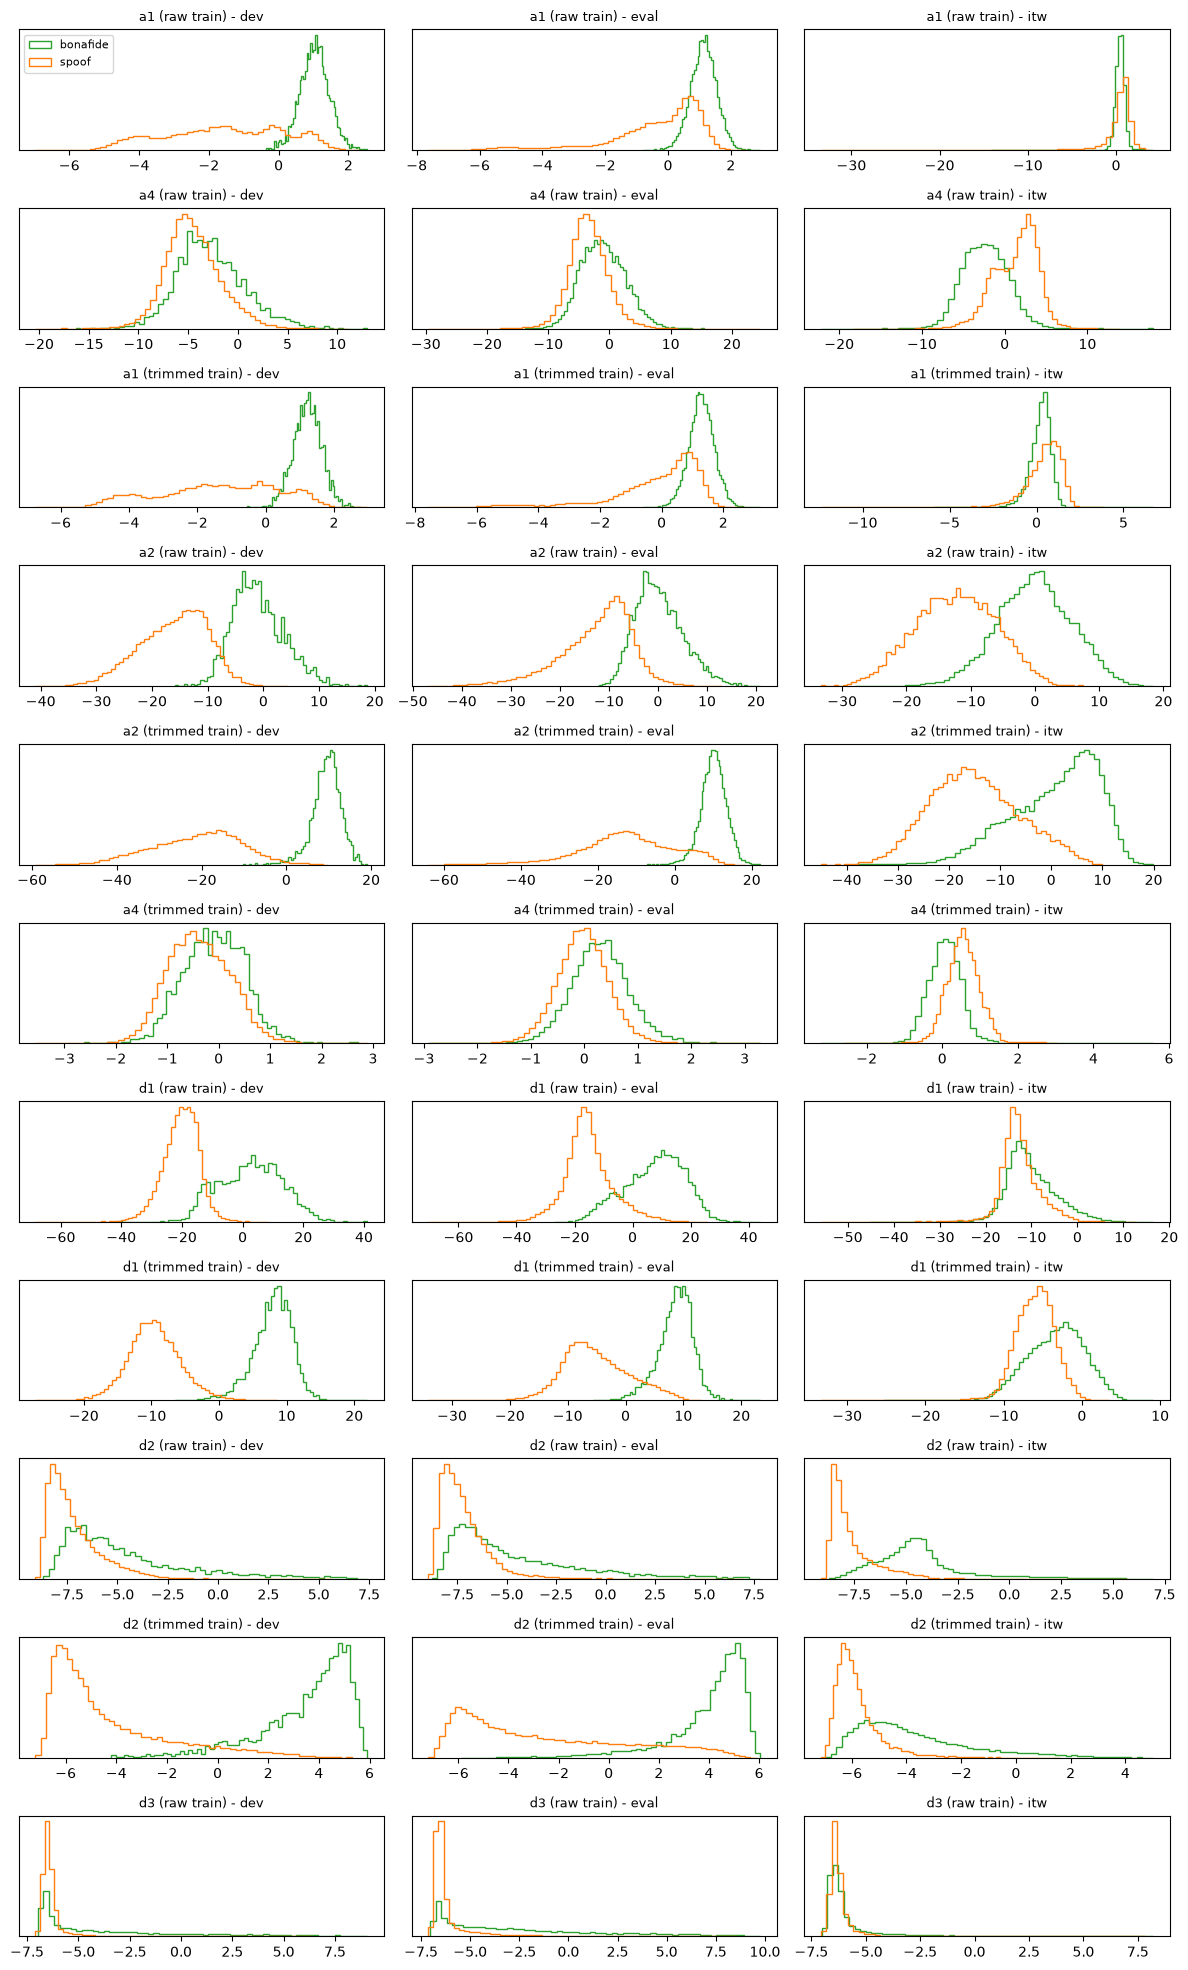

In [4]:
sets = ["dev", "eval", "itw"]
fig, axes = plt.subplots(len(results), len(sets), figsize=(12, 1.8 * len(results)), squeeze=False)
for i, (k, v) in enumerate(results.items()):
    v = v["scores"]
    for j, t in enumerate(sets):
        ax = axes[i, j]
        for lab, color in [("bonafide", "tab:green"), ("spoof", "tab:orange")]:
            ax.hist(v[t].score[v[t].label == lab], bins=60, density=True, histtype="step", color=color, label=lab)
        ax.set_title(f"{k[0]} ({k[1]} train) - {t}", fontsize=9)
        ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()